
# 22 — Scorer × generator/source-condition factorization

## Question

The context-range trace is scorer-relative by construction:

\[
L_k^{(s)}(x)
=
-\mathbb{E}_{t\in T}
\log q_s(x_t\mid x_{t-k:t-1}),
\qquad
U^{(s)}_x(k)=L^{(s)}_8(x)-L^{(s)}_k(x).
\]

We now ask which aspects of the measured trace are properties of the **completed text**
and which depend on the **independent observation model** \(q_s\).

The main scientific question is:

> Are source/generator contrasts preserved across independent scorers even when absolute
> loss levels and response scales differ?

This is deliberately **not** another dense-CLP experiment. Dense resolution was already
characterized in notebooks 11--21. Here we use only the frozen paper contexts

\[
k\in\{8,32,128,256\},
\]

which is sufficient to study scorer dependence of the original context-utility trace
while keeping the experiment practical on an 8 GB RTX 2000 Ada.

## Design

We use the fully matched Ghostbuster essay corpus. It contains seven source conditions
for each essay ID:

- human
- gpt
- claude
- gpt_prompt1
- gpt_prompt2
- gpt_semantic
- gpt_writing

The prompt variants are **source conditions**, not seven independent model families.
The notebook therefore reports both all-condition analyses and machine-only analyses,
without treating prompt variants as independent generator families.

Three small frozen scorers are run **sequentially**:

1. `Qwen/Qwen3-0.6B-Base` — paper scorer
2. `gpt2` — established robustness scorer
3. `HuggingFaceTB/SmolLM2-360M` — optional third architecture/family

No two scorers are resident on GPU simultaneously. Each scorer saves a separate parquet
checkpoint and can be resumed independently.

### Primary hypotheses

**H1 — Source contrast invariance.**  
Relative source-condition signatures should agree across scorers more strongly than
absolute \(L_k\) levels do.

**H2 — Human/machine contrast robustness.**  
For each \(U(k)\), machine-minus-human contrasts should usually preserve direction
across scorers if the trace reflects a property of the completed output rather than
only scorer idiosyncrasy.

**H3 — Scorer × source interaction is nonzero but secondary.**  
We expect scorer-dependent observation geometry, but not complete reordering of source
conditions.

**H4 — Document-level agreement is weaker than aggregate contrast agreement.**  
Different tokenizers and predictive models need not rank individual documents
identically even if aggregate source contrasts are stable.

The intended interpretation is therefore:

\[
\boxed{
\text{source-dependent output property}
\;\xrightarrow{\text{scorer-specific observation}}\;
U^{(s)}(k)
}
\]

rather than literal recovery of source-model internals.


In [1]:

from pathlib import Path
import gc
import inspect
import json
import time

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd

DATA = ROOT / "data"
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"

RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

ESSAY_PATH = DATA / "raw" / "ghostbuster_essays.parquet"
assert ESSAY_PATH.exists(), ESSAY_PATH

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("ROOT:", ROOT)
print("device:", DEVICE)

if DEVICE == "cuda":
    props = torch.cuda.get_device_properties(0)
    print("GPU:", props.name)
    print("VRAM GiB:", round(props.total_memory / 2**30, 2))


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ROOT: ..
device: cuda
GPU: NVIDIA RTX 2000 Ada Generation Laptop GPU
VRAM GiB: 7.62



## Compute-bounded configuration

The expensive quantity is approximately

\[
N_{\mathrm{groups}}
\times 7\ \mathrm{conditions}
\times 3\ \mathrm{scorers}
\times 4\ \mathrm{contexts}.
\]

Each context call batches all eight deterministic target positions together.

The default `N_GROUPS = 64` is intentional. It gives

\[
64\times7=448
\]

documents per scorer, enough for matched-source bootstrap diagnostics while keeping the
first pass manageable on an 8 GB workstation GPU.

If the first two scorers run comfortably and the results are important, increase this
to 96 or 128 in a later confirmatory rerun. Do **not** increase resolution to dense CLP;
that does not answer the present question.


In [2]:

# ------------------------------------------------------------------
# FROZEN MEASUREMENT SETTINGS
# ------------------------------------------------------------------

PREFIX_LEN = 384
CONTEXT_LENGTHS = [8, 32, 128, 256]
N_CONTEXT_TARGETS = 8

# 64 is the compute-bounded default.
N_GROUPS = 128
SUBSET_SEED = 2201

# Each scorer is loaded and unloaded independently.
SCORERS = {
    "Qwen3-0.6B": {
        "model_id": "Qwen/Qwen3-0.6B-Base",
        "batch_size": 8,
        "required": True,
    },
    "GPT-2": {
        "model_id": "gpt2",
        "batch_size": 8,
        "required": True,
    },
    "SmolLM2-360M": {
        "model_id": "HuggingFaceTB/SmolLM2-360M",
        "batch_size": 8,
        # Set False if the first two scorers already take too long.
        # A two-scorer matrix is still scientifically useful.
        "required": True,
    },
}

SOURCE_ORDER = [
    "human",
    "gpt",
    "claude",
    "gpt_prompt1",
    "gpt_prompt2",
    "gpt_semantic",
    "gpt_writing",
]

MANIFEST_PATH = RESULTS / "scorer_generator_manifest.parquet"
COMBINED_PATH = RESULTS / "scorer_generator_context_utility.parquet"

print(json.dumps(SCORERS, indent=2))


{
  "Qwen3-0.6B": {
    "model_id": "Qwen/Qwen3-0.6B-Base",
    "batch_size": 8,
    "required": true
  },
  "GPT-2": {
    "model_id": "gpt2",
    "batch_size": 8,
    "required": true
  },
  "SmolLM2-360M": {
    "model_id": "HuggingFaceTB/SmolLM2-360M",
    "batch_size": 8,
    "required": true
  }
}



## Load the matched Ghostbuster essay corpus

`ghostbuster_essays.parquet` was built in notebook 00c and contains exactly 1,000 matched
essay IDs across the seven source conditions.


In [3]:

raw = pd.read_parquet(ESSAY_PATH).copy()

required_cols = {
    "row_id",
    "group_id",
    "generator",
    "text",
}

missing = required_cols - set(raw.columns)
assert not missing, f"Missing columns: {sorted(missing)}"

raw["group_id"] = raw["group_id"].astype(str)

print("shape:", raw.shape)
display(raw.groupby("generator").size().rename("n").to_frame())

group_counts = raw.groupby("group_id")["generator"].nunique()
assert (group_counts == len(SOURCE_ORDER)).all()

print("fully matched groups:", len(group_counts))


shape: (7000, 8)


,n
generator,
claude,1000
gpt,1000
gpt_prompt1,1000
gpt_prompt2,1000
gpt_semantic,1000
gpt_writing,1000
human,1000


fully matched groups: 1000



## Common eligibility across all scorers

Cross-scorer comparison should not silently compare different document subsets.

We therefore require every selected source group to have all seven conditions long
enough for the 384-token prefix **under every scorer tokenizer**.

Eligibility only needs tokenization, not model inference. Tokenizers are loaded one at
a time on CPU.


In [4]:

def capped_token_lengths(texts, tokenizer, cap=PREFIX_LEN, batch_size=64):
    lengths = []

    for start in tqdm(
        range(0, len(texts), batch_size),
        desc="token lengths",
        leave=False,
    ):
        batch = [str(x) for x in texts[start:start + batch_size]]

        enc = tokenizer(
            batch,
            add_special_tokens=False,
            truncation=True,
            max_length=cap,
            padding=False,
        )

        lengths.extend(len(ids) for ids in enc["input_ids"])

    return np.asarray(lengths, dtype=int)


eligibility = raw[
    ["row_id", "group_id", "generator", "text"]
].copy()

for scorer, cfg in SCORERS.items():
    print("\nTokenizer:", scorer, cfg["model_id"])

    tok = AutoTokenizer.from_pretrained(
        cfg["model_id"],
        use_fast=True,
    )

    eligibility[f"n_tok_{scorer}"] = capped_token_lengths(
        eligibility["text"].tolist(),
        tok,
    )

    eligibility[f"eligible_{scorer}"] = (
        eligibility[f"n_tok_{scorer}"] >= PREFIX_LEN
    )

    del tok
    gc.collect()

eligible_cols = [
    f"eligible_{s}"
    for s in SCORERS
]

eligibility["eligible_all_scorers"] = eligibility[
    eligible_cols
].all(axis=1)

group_ok = (
    eligibility
    .groupby("group_id")["eligible_all_scorers"]
    .all()
)

eligible_groups = np.array(
    sorted(group_ok.index[group_ok])
)

print("\nGroups eligible across every condition and scorer:",
      len(eligible_groups))

assert len(eligible_groups) >= N_GROUPS, (
    f"Only {len(eligible_groups)} groups are jointly eligible; "
    f"reduce N_GROUPS from {N_GROUPS}."
)



Tokenizer: Qwen3-0.6B Qwen/Qwen3-0.6B-Base



Tokenizer: GPT-2 gpt2



Tokenizer: SmolLM2-360M HuggingFaceTB/SmolLM2-360M



Groups eligible across every condition and scorer: 695


In [5]:

# Deterministic matched subset.
rng = np.random.RandomState(SUBSET_SEED)

selected_groups = np.sort(
    rng.choice(
        eligible_groups,
        size=N_GROUPS,
        replace=False,
    )
)

manifest = (
    eligibility[
        eligibility["group_id"].isin(selected_groups)
    ]
    .drop(columns=["text"])
    .sort_values(["group_id", "generator"])
    .reset_index(drop=True)
)

manifest["subset_seed"] = SUBSET_SEED
manifest["prefix_len"] = PREFIX_LEN
manifest["n_targets"] = N_CONTEXT_TARGETS

manifest.to_parquet(
    MANIFEST_PATH,
    index=False,
)

subset = (
    raw[
        raw["group_id"].isin(selected_groups)
    ]
    .copy()
    .sort_values(["group_id", "generator"])
    .reset_index(drop=True)
)

assert len(subset) == N_GROUPS * len(SOURCE_ORDER)

print("selected groups:", N_GROUPS)
print("documents per scorer:", len(subset))
print("saved:", MANIFEST_PATH)

display(
    subset.groupby("generator").size().rename("n").to_frame()
)


selected groups: 128
documents per scorer: 896
saved: ../results/scorer_generator_manifest.parquet


,n
generator,
claude,128
gpt,128
gpt_prompt1,128
gpt_prompt2,128
gpt_semantic,128
gpt_writing,128
human,128



## Generic memory-safe scorer

This is the notebook-00a measurement generalized across causal LMs.

For each document:

1. tokenize and retain the first 384 scorer tokens;
2. choose the same eight deterministic positions from token 256 to 383;
3. for each \(k\in\{8,32,128,256\}\), batch the eight \(k\)-token histories;
4. score only the target next token.

For models exposing `logits_to_keep`, only the final logits are materialized. Other small
models fall back to their standard forward pass.

The scorer loop checkpoints after every 25 documents. If a run is interrupted, rerun
the cell and it resumes from the existing parquet.


In [6]:

def scorer_slug(name):
    return (
        name.lower()
        .replace(".", "")
        .replace("-", "_")
        .replace("/", "_")
    )


def scorer_output_path(scorer):
    return RESULTS / f"scorer_generator_{scorer_slug(scorer)}.parquet"


@torch.inference_mode()
def score_document(
    text,
    tokenizer,
    model,
    batch_size,
    supports_logits_to_keep,
):
    ids = tokenizer(
        str(text),
        add_special_tokens=False,
        return_tensors="pt",
        truncation=True,
        max_length=PREFIX_LEN,
    )["input_ids"][0]

    if len(ids) < PREFIX_LEN:
        return None

    ids = ids[:PREFIX_LEN]

    max_k = max(CONTEXT_LENGTHS)

    target_positions = np.linspace(
        max_k,
        len(ids) - 1,
        N_CONTEXT_TARGETS,
        dtype=int,
    )
    target_positions = np.unique(target_positions)

    if len(target_positions) != N_CONTEXT_TARGETS:
        raise RuntimeError(
            "Target-position rounding produced duplicates."
        )

    result = {}

    for k in CONTEXT_LENGTHS:
        sequences = torch.stack([
            ids[pos-k:pos]
            for pos in target_positions
        ])

        targets = torch.stack([
            ids[pos]
            for pos in target_positions
        ])

        total_nll = 0.0
        total_count = 0

        for start in range(
            0,
            len(sequences),
            batch_size,
        ):
            x = sequences[
                start:start + batch_size
            ].to(DEVICE)

            y = targets[
                start:start + batch_size
            ].to(DEVICE)

            kwargs = {"input_ids": x}

            if supports_logits_to_keep:
                kwargs["logits_to_keep"] = 1

            out = model(**kwargs)

            logits = out.logits[:, -1, :].float()

            log_probs = torch.log_softmax(
                logits,
                dim=-1,
            )

            idx = torch.arange(
                len(y),
                device=DEVICE,
            )

            nll = -log_probs[idx, y]

            total_nll += float(nll.sum().item())
            total_count += len(y)

            del x, y, out, logits, log_probs, nll

        result[f"L_{k}"] = (
            total_nll / total_count
        )

    for k in [32, 128, 256]:
        result[f"U_{k}"] = (
            result["L_8"]
            - result[f"L_{k}"]
        )

    return result



### Sequential scoring

The cell below is the only expensive step.

Expected behavior on the 8 GB workstation:

- only one model exists on GPU at once;
- Qwen uses `logits_to_keep=1`;
- each forward pass contains at most eight sequences;
- results are checkpointed per scorer;
- GPU memory is explicitly released before the next scorer.

If a scorer OOMs, lower only its configured `batch_size` from 8 to 4 and rerun. Since
checkpoints are incremental, completed rows are retained.


In [7]:

all_outputs = []

for scorer, cfg in SCORERS.items():
    path = scorer_output_path(scorer)

    print("\n" + "=" * 72)
    print("SCORER:", scorer)
    print("MODEL:", cfg["model_id"])
    print("checkpoint:", path)

    if path.exists():
        done = pd.read_parquet(path)
        print("existing rows:", len(done))
    else:
        done = pd.DataFrame()

    done_ids = (
        set(done["row_id"])
        if len(done)
        else set()
    )

    remaining = subset[
        ~subset["row_id"].isin(done_ids)
    ].copy()

    if len(remaining) == 0:
        print("already complete")
        all_outputs.append(done)
        continue

    tokenizer = AutoTokenizer.from_pretrained(
        cfg["model_id"],
        use_fast=True,
    )

    # Match the original U(k) implementation on GPU:
    # FP16 weights, FP32 log-softmax/NLL.
    dtype = (
        torch.float16
        if DEVICE == "cuda"
        else torch.float32
    )

    model = AutoModelForCausalLM.from_pretrained(
        cfg["model_id"],
        torch_dtype=dtype,
    )

    model.eval()
    model.to(DEVICE)

    sig = inspect.signature(model.forward)

    supports_logits_to_keep = (
        "logits_to_keep" in sig.parameters
    )

    print("supports logits_to_keep:",
          supports_logits_to_keep)

    if DEVICE == "cuda":
        torch.cuda.empty_cache()
        print(
            "allocated GiB:",
            round(torch.cuda.memory_allocated() / 2**30, 3),
        )

    new_rows = []
    t0 = time.time()

    for n, r in enumerate(
        tqdm(
            remaining.itertuples(index=False),
            total=len(remaining),
            desc=scorer,
        ),
        start=1,
    ):
        feats = score_document(
            r.text,
            tokenizer=tokenizer,
            model=model,
            batch_size=cfg["batch_size"],
            supports_logits_to_keep=supports_logits_to_keep,
        )

        if feats is None:
            raise RuntimeError(
                f"Manifest said eligible but scoring failed: {r.row_id}"
            )

        row = {
            "row_id": r.row_id,
            "group_id": str(r.group_id),
            "generator": r.generator,
            "scorer": scorer,
            "model_id": cfg["model_id"],
            "prefix_len": PREFIX_LEN,
            "n_targets": N_CONTEXT_TARGETS,
            **feats,
        }

        new_rows.append(row)

        if (
            n % 25 == 0
            or n == len(remaining)
        ):
            block = pd.DataFrame(new_rows)

            merged = pd.concat(
                [done, block],
                ignore_index=True,
            )

            merged = (
                merged
                .drop_duplicates(
                    subset=["row_id"],
                    keep="last",
                )
                .sort_values(
                    ["group_id", "generator"]
                )
                .reset_index(drop=True)
            )

            merged.to_parquet(
                path,
                index=False,
            )

            done = merged
            new_rows = []

    elapsed = time.time() - t0

    print(
        f"{scorer}: {len(done)} docs, "
        f"{elapsed/60:.1f} min this session"
    )

    all_outputs.append(done)

    # Critical for 8 GB GPUs: release scorer before loading the next.
    del model, tokenizer
    gc.collect()

    if DEVICE == "cuda":
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()

        print(
            "allocated after unload GiB:",
            round(torch.cuda.memory_allocated() / 2**30, 3),
        )



SCORER: Qwen3-0.6B
MODEL: Qwen/Qwen3-0.6B-Base
checkpoint: ../results/scorer_generator_qwen3_06b.parquet
existing rows: 896
already complete

SCORER: GPT-2
MODEL: gpt2
checkpoint: ../results/scorer_generator_gpt_2.parquet
existing rows: 896
already complete

SCORER: SmolLM2-360M
MODEL: HuggingFaceTB/SmolLM2-360M
checkpoint: ../results/scorer_generator_smollm2_360m.parquet
existing rows: 896
already complete



## Combine and audit completeness


In [8]:

parts = []

for scorer in SCORERS:
    path = scorer_output_path(scorer)
    assert path.exists(), f"Missing scorer result: {path}"

    x = pd.read_parquet(path)

    # Only this experiment's frozen subset.
    x = x[
        x["row_id"].isin(subset["row_id"])
    ].copy()

    parts.append(x)

scores = pd.concat(
    parts,
    ignore_index=True,
)

scores.to_parquet(
    COMBINED_PATH,
    index=False,
)

expected = (
    N_GROUPS
    * len(SOURCE_ORDER)
    * len(SCORERS)
)

print("rows:", len(scores), "/", expected)
assert len(scores) == expected

audit = (
    scores
    .groupby(["scorer", "generator"])
    .size()
    .unstack()
    .reindex(
        index=list(SCORERS),
        columns=SOURCE_ORDER,
    )
)

display(audit)

assert (audit == N_GROUPS).all().all()

print("saved:", COMBINED_PATH)


rows: 2688 / 2688


generator,human,gpt,claude,gpt_prompt1,gpt_prompt2,gpt_semantic,gpt_writing
scorer,,,,,,,
Qwen3-0.6B,128,128,128,128,128,128,128
GPT-2,128,128,128,128,128,128,128
SmolLM2-360M,128,128,128,128,128,128,128


saved: ../results/scorer_generator_context_utility.parquet



# Analysis

The analysis separates three notions that should not be conflated:

### 1. Absolute scorer response

\[
L_k^{(s,g)}
\]

is expected to vary substantially with scorer calibration and tokenizer.

### 2. Context-utility source signature

\[
U^{(s,g)}(k)
\]

asks whether source conditions are ordered similarly across scorers.

### 3. Relative-to-human source contrast

\[
\Delta^{(s,g)}_k
=
\mathbb E_i[
U^{(s)}_{i,g}(k)
-
U^{(s)}_{i,\mathrm{human}}(k)
].
\]

Because every source condition is paired by the same essay ID \(i\), this is the cleanest
cross-scorer construct-robustness quantity.


In [9]:

METRICS = [
    "L_8",
    "L_32",
    "L_128",
    "L_256",
    "U_32",
    "U_128",
    "U_256",
]

cell_means = (
    scores
    .groupby(["scorer", "generator"])[METRICS]
    .mean()
    .reset_index()
)

display(cell_means.head(14))


,scorer,generator,L_8,L_32,L_128,L_256,U_32,U_128,U_256
0,GPT-2,claude,4.069614,3.407754,3.056106,2.915584,0.661860,1.013507,1.154029
1,GPT-2,gpt,3.893938,3.152362,2.653124,2.505620,0.741576,1.240813,1.388318
2,GPT-2,gpt_prompt1,4.380166,3.527018,2.844898,2.595443,0.853149,1.535268,1.784724
3,GPT-2,gpt_prompt2,4.046463,3.198748,2.618059,2.456920,0.847715,1.428404,1.589543
4,GPT-2,gpt_semantic,3.917277,3.202650,2.666070,2.492807,0.714627,1.251208,1.424470
5,GPT-2,gpt_writing,4.167339,3.262348,2.580624,2.368517,0.904991,1.586715,1.798822
6,GPT-2,human,4.537086,3.973554,3.587342,3.384579,0.563532,0.949744,1.152507
7,Qwen3-0.6B,claude,3.708478,2.834092,2.361873,2.227079,0.874387,1.346606,1.481400
8,Qwen3-0.6B,gpt,3.104367,2.232637,1.683911,1.531092,0.871730,1.420455,1.573274
9,Qwen3-0.6B,gpt_prompt1,3.337196,2.291195,1.747502,1.561050,1.046001,1.589695,1.776147



## A. Source-condition signatures across scorers

For each metric, correlate the seven-condition vector across scorers.

We report both:

- **all seven source conditions**, including human;
- **machine-only six conditions**, to ensure a high correlation is not driven solely by
  a human/machine separation.

Pearson measures approximately affine agreement; Spearman measures ranking agreement.


In [10]:

from itertools import combinations

signature_rows = []

for metric in METRICS:
    pivot = (
        cell_means
        .pivot(
            index="generator",
            columns="scorer",
            values=metric,
        )
        .reindex(SOURCE_ORDER)
    )

    for s1, s2 in combinations(SCORERS, 2):
        for scope, gens in [
            ("all", SOURCE_ORDER),
            (
                "machine_only",
                [g for g in SOURCE_ORDER if g != "human"],
            ),
        ]:
            a = pivot.loc[gens, s1]
            b = pivot.loc[gens, s2]

            signature_rows.append({
                "metric": metric,
                "scope": scope,
                "scorer_1": s1,
                "scorer_2": s2,
                "pearson": a.corr(b, method="pearson"),
                "spearman": a.corr(b, method="spearman"),
            })

signature_agreement = pd.DataFrame(
    signature_rows
)

display(
    signature_agreement[
        signature_agreement["metric"].isin(
            ["U_32", "U_128", "U_256"]
        )
    ]
)


,metric,scope,scorer_1,scorer_2,pearson,spearman
24,U_32,all,Qwen3-0.6B,GPT-2,0.890889,0.857143
25,U_32,machine_only,Qwen3-0.6B,GPT-2,0.786422,0.771429
26,U_32,all,Qwen3-0.6B,SmolLM2-360M,0.917792,0.857143
27,U_32,machine_only,Qwen3-0.6B,SmolLM2-360M,0.701001,0.771429
28,U_32,all,GPT-2,SmolLM2-360M,0.713762,0.642857
29,U_32,machine_only,GPT-2,SmolLM2-360M,0.312415,0.428571
30,U_128,all,Qwen3-0.6B,GPT-2,0.940809,1.000000
31,U_128,machine_only,Qwen3-0.6B,GPT-2,0.971341,1.000000
32,U_128,all,Qwen3-0.6B,SmolLM2-360M,0.959025,0.928571
33,U_128,machine_only,Qwen3-0.6B,SmolLM2-360M,0.873486,0.885714



## B. Matched generator/source contrasts relative to human

This is the primary robustness analysis.

For every scorer and source ID:

\[
\delta_{i,s,g}(k)
=
U_{i,s,g}(k)-U_{i,s,\mathrm{human}}(k).
\]

The same source ID therefore acts as its own control.


In [11]:

U_METRICS = ["U_32", "U_128", "U_256"]

wide = scores.pivot_table(
    index=["group_id", "scorer"],
    columns="generator",
    values=U_METRICS,
)

contrast_rows = []

for scorer in SCORERS:
    sw = wide.xs(
        scorer,
        level="scorer",
    )

    for metric in U_METRICS:
        for generator in [
            g for g in SOURCE_ORDER
            if g != "human"
        ]:
            delta = (
                sw[(metric, generator)]
                - sw[(metric, "human")]
            )

            for group_id, value in delta.items():
                contrast_rows.append({
                    "group_id": str(group_id),
                    "scorer": scorer,
                    "metric": metric,
                    "generator": generator,
                    "delta_vs_human": float(value),
                })

contrasts = pd.DataFrame(
    contrast_rows
)

contrast_summary = (
    contrasts
    .groupby(
        ["metric", "generator", "scorer"]
    )["delta_vs_human"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

display(
    contrast_summary[
        contrast_summary["metric"] == "U_256"
    ]
)


,metric,generator,scorer,mean,std,count
18,U_256,claude,GPT-2,0.001522,0.917735,128
19,U_256,claude,Qwen3-0.6B,0.232970,1.133845,128
20,U_256,claude,SmolLM2-360M,0.374432,0.971944,128
21,U_256,gpt,GPT-2,0.235811,1.147407,128
22,U_256,gpt,Qwen3-0.6B,0.324845,1.059018,128
23,U_256,gpt,SmolLM2-360M,0.394459,1.061060,128
24,U_256,gpt_prompt1,GPT-2,0.632217,1.423016,128
25,U_256,gpt_prompt1,Qwen3-0.6B,0.527717,1.288727,128
26,U_256,gpt_prompt1,SmolLM2-360M,0.726391,1.197475,128
27,U_256,gpt_prompt2,GPT-2,0.437036,1.124750,128



## C. Matched-source bootstrap uncertainty

Bootstrap the 64 essay IDs, preserving every scorer and source condition within each
resampled ID.

For each resample we compute:

1. each machine-minus-human contrast;
2. cross-scorer correlation of the machine-source signature;
3. an additive scorer + source decomposition of the \(S\times G\) mean matrix.

The additive decomposition is descriptive:

\[
Y_{s,g}
=
\mu+A_s+B_g+I_{s,g},
\]

where \(I_{s,g}\) is the scorer × source interaction. We report

\[
\rho_I
=
\frac{\sum_{s,g} I_{s,g}^2}
{\sum_{s,g}(Y_{s,g}-\mu)^2}.
\]

A small value means the aggregate cell means are approximately additive. It is not a
mixed-effects model or a causal variance component.


In [12]:

N_BOOT = 2000
BOOT_SEED = 2202

group_ids = np.array(
    sorted(scores["group_id"].unique())
)

rng = np.random.RandomState(
    BOOT_SEED
)

boot_rows = []
interaction_rows = []
signature_boot_rows = []


def additive_interaction_fraction(mat):
    mat = np.asarray(mat, dtype=float)

    grand = mat.mean()
    scorer_mean = mat.mean(axis=1, keepdims=True)
    source_mean = mat.mean(axis=0, keepdims=True)

    additive = (
        scorer_mean
        + source_mean
        - grand
    )

    interaction = mat - additive

    denom = np.square(
        mat - grand
    ).sum()

    if denom <= 0:
        return np.nan

    return (
        np.square(interaction).sum()
        / denom
    )


for b in tqdm(
    range(N_BOOT),
    desc="matched-source bootstrap",
):
    sampled = rng.choice(
        group_ids,
        size=len(group_ids),
        replace=True,
    )

    # Duplicated groups need multiplicity. Building a concatenated
    # bootstrap table is still cheap: only 64*7*3 rows.
    chunks = [
        scores[
            scores["group_id"] == gid
        ]
        for gid in sampled
    ]

    bs = pd.concat(
        chunks,
        ignore_index=True,
    )

    means = (
        bs
        .groupby(["scorer", "generator"])[U_METRICS]
        .mean()
    )

    # Contrasts relative to human.
    for metric in U_METRICS:
        for scorer in SCORERS:
            for generator in [
                g for g in SOURCE_ORDER
                if g != "human"
            ]:
                value = (
                    means.loc[
                        (scorer, generator),
                        metric,
                    ]
                    - means.loc[
                        (scorer, "human"),
                        metric,
                    ]
                )

                boot_rows.append({
                    "boot": b,
                    "metric": metric,
                    "scorer": scorer,
                    "generator": generator,
                    "delta_vs_human": value,
                })

        # S x G matrix interaction.
        mat = (
            means[metric]
            .unstack("generator")
            .reindex(
                index=list(SCORERS),
                columns=SOURCE_ORDER,
            )
            .to_numpy()
        )

        interaction_rows.append({
            "boot": b,
            "metric": metric,
            "interaction_fraction":
                additive_interaction_fraction(mat),
        })

        # Machine-only source signature agreement.
        machine = [
            g for g in SOURCE_ORDER
            if g != "human"
        ]

        piv = (
            means[metric]
            .unstack("scorer")
            .reindex(machine)
        )

        for s1, s2 in combinations(SCORERS, 2):
            signature_boot_rows.append({
                "boot": b,
                "metric": metric,
                "scorer_1": s1,
                "scorer_2": s2,
                "pearson_machine": piv[s1].corr(
                    piv[s2],
                    method="pearson",
                ),
                "spearman_machine": piv[s1].corr(
                    piv[s2],
                    method="spearman",
                ),
            })


boot_contrasts = pd.DataFrame(boot_rows)
boot_interaction = pd.DataFrame(interaction_rows)
boot_signatures = pd.DataFrame(signature_boot_rows)

boot_contrasts.to_csv(
    RESULTS / "scorer_generator_contrast_bootstrap.csv",
    index=False,
)

boot_interaction.to_csv(
    RESULTS / "scorer_generator_interaction_bootstrap.csv",
    index=False,
)

boot_signatures.to_csv(
    RESULTS / "scorer_generator_signature_bootstrap.csv",
    index=False,
)


matched-source bootstrap: 100%|█████████████████████████████████████████████████████████████████████| 2000/2000 [02:37<00:00, 12.72it/s]


In [13]:

contrast_ci = (
    boot_contrasts
    .groupby(
        ["metric", "generator", "scorer"]
    )["delta_vs_human"]
    .agg(
        boot_mean="mean",
        ci_low=lambda x: np.quantile(x, 0.025),
        ci_high=lambda x: np.quantile(x, 0.975),
    )
    .reset_index()
)

interaction_ci = (
    boot_interaction
    .groupby("metric")["interaction_fraction"]
    .agg(
        median="median",
        ci_low=lambda x: np.quantile(x, 0.025),
        ci_high=lambda x: np.quantile(x, 0.975),
    )
    .reset_index()
)

signature_ci = (
    boot_signatures
    .groupby(
        ["metric", "scorer_1", "scorer_2"]
    )
    .agg(
        pearson_median=(
            "pearson_machine",
            "median",
        ),
        pearson_low=(
            "pearson_machine",
            lambda x: np.quantile(x, 0.025),
        ),
        pearson_high=(
            "pearson_machine",
            lambda x: np.quantile(x, 0.975),
        ),
        spearman_median=(
            "spearman_machine",
            "median",
        ),
        spearman_low=(
            "spearman_machine",
            lambda x: np.quantile(x, 0.025),
        ),
        spearman_high=(
            "spearman_machine",
            lambda x: np.quantile(x, 0.975),
        ),
    )
    .reset_index()
)

contrast_ci.to_csv(
    RESULTS / "scorer_generator_contrast_summary.csv",
    index=False,
)
interaction_ci.to_csv(
    RESULTS / "scorer_generator_interaction_summary.csv",
    index=False,
)
signature_ci.to_csv(
    RESULTS / "scorer_generator_signature_summary.csv",
    index=False,
)

print("Machine-minus-human contrasts:")
display(contrast_ci)

print("\nScorer × source interaction fraction:")
display(interaction_ci)

print("\nMachine-only signature agreement:")
display(signature_ci)


Machine-minus-human contrasts:


,metric,generator,scorer,boot_mean,ci_low,ci_high
0,U_128,claude,GPT-2,0.061824,-0.081796,0.206637
1,U_128,claude,Qwen3-0.6B,0.204599,0.017940,0.393259
2,U_128,claude,SmolLM2-360M,0.329217,0.166760,0.483804
3,U_128,gpt,GPT-2,0.291819,0.105446,0.475243
4,U_128,gpt,Qwen3-0.6B,0.281175,0.120736,0.444476
5,U_128,gpt,SmolLM2-360M,0.308629,0.130620,0.495601
6,U_128,gpt_prompt1,GPT-2,0.583106,0.354428,0.823905
7,U_128,gpt_prompt1,Qwen3-0.6B,0.447162,0.243528,0.665481
8,U_128,gpt_prompt1,SmolLM2-360M,0.587389,0.404772,0.780227
9,U_128,gpt_prompt2,GPT-2,0.475339,0.281312,0.661669



Scorer × source interaction fraction:


,metric,median,ci_low,ci_high
0,U_128,0.124326,0.056716,0.225534
1,U_256,0.128282,0.062103,0.226093
2,U_32,0.141508,0.065958,0.253246



Machine-only signature agreement:


,metric,scorer_1,scorer_2,pearson_median,pearson_low,pearson_high,spearman_median,spearman_low,spearman_high
0,U_128,GPT-2,SmolLM2-360M,0.716817,0.196908,0.951488,0.771429,0.085714,1.000000
1,U_128,Qwen3-0.6B,GPT-2,0.827568,0.408885,0.973854,0.828571,0.314286,1.000000
2,U_128,Qwen3-0.6B,SmolLM2-360M,0.712535,0.105748,0.953941,0.657143,0.028571,0.942857
3,U_256,GPT-2,SmolLM2-360M,0.749586,0.299772,0.961472,0.771429,0.142857,1.000000
4,U_256,Qwen3-0.6B,GPT-2,0.863027,0.531922,0.980750,0.828571,0.428571,1.000000
5,U_256,Qwen3-0.6B,SmolLM2-360M,0.657279,0.079740,0.930261,0.657143,-0.085714,1.000000
6,U_32,GPT-2,SmolLM2-360M,0.274110,-0.464379,0.820541,0.257143,-0.542857,0.828571
7,U_32,Qwen3-0.6B,GPT-2,0.617139,-0.006997,0.929109,0.600000,-0.085714,0.942857
8,U_32,Qwen3-0.6B,SmolLM2-360M,0.507931,-0.225543,0.911131,0.485714,-0.314286,0.942857



## D. Directional stability across scorers

A simple construct-validity diagnostic is whether each source condition has the same
sign relative to human under all independent scorers.

This is intentionally stricter than asking whether one pooled classifier performs well.


In [14]:

direction_rows = []

point_contrasts = (
    contrasts
    .groupby(
        ["metric", "generator", "scorer"]
    )["delta_vs_human"]
    .mean()
    .unstack("scorer")
)

for (metric, generator), row in point_contrasts.iterrows():
    vals = row[list(SCORERS)].to_numpy(dtype=float)
    signs = np.sign(vals)

    direction_rows.append({
        "metric": metric,
        "generator": generator,
        "all_same_sign":
            bool(np.all(signs == signs[0])),
        "min_abs_delta":
            float(np.min(np.abs(vals))),
        **{
            f"delta_{s}": row[s]
            for s in SCORERS
        },
    })

direction_stability = pd.DataFrame(
    direction_rows
)

display(direction_stability)


,metric,generator,all_same_sign,min_abs_delta,delta_Qwen3-0.6B,delta_GPT-2,delta_SmolLM2-360M
0,U_128,claude,True,0.063763,0.205740,0.063763,0.329487
1,U_128,gpt,True,0.279590,0.279590,0.291069,0.309933
2,U_128,gpt_prompt1,True,0.448830,0.448830,0.585524,0.592197
3,U_128,gpt_prompt2,True,0.343599,0.343599,0.478660,0.384904
4,U_128,gpt_semantic,True,0.301464,0.318902,0.301464,0.345056
5,U_128,gpt_writing,True,0.473891,0.473891,0.636971,0.495338
6,U_256,claude,True,0.001522,0.232970,0.001522,0.374432
7,U_256,gpt,True,0.235811,0.324845,0.235811,0.394459
8,U_256,gpt_prompt1,True,0.527717,0.527717,0.632217,0.726391
9,U_256,gpt_prompt2,True,0.437036,0.470624,0.437036,0.452223



## E. Document-level cross-scorer agreement

Aggregate source effects may be scorer-robust even if individual-document rankings are
not.

For every source condition and \(U(k)\), correlate the 64 matched document values across
scorer pairs.


In [15]:

doc_agreement_rows = []

for metric in U_METRICS:
    for generator in SOURCE_ORDER:
        q = (
            scores[
                scores["generator"] == generator
            ]
            .pivot(
                index="group_id",
                columns="scorer",
                values=metric,
            )
        )

        for s1, s2 in combinations(SCORERS, 2):
            doc_agreement_rows.append({
                "metric": metric,
                "generator": generator,
                "scorer_1": s1,
                "scorer_2": s2,
                "pearson": q[s1].corr(
                    q[s2],
                    method="pearson",
                ),
                "spearman": q[s1].corr(
                    q[s2],
                    method="spearman",
                ),
            })

doc_agreement = pd.DataFrame(
    doc_agreement_rows
)

doc_agreement.to_csv(
    RESULTS / "scorer_generator_document_agreement.csv",
    index=False,
)

display(
    doc_agreement[
        doc_agreement["metric"] == "U_256"
    ]
)


,metric,generator,scorer_1,scorer_2,pearson,spearman
42,U_256,human,Qwen3-0.6B,GPT-2,-0.013168,-0.032154
43,U_256,human,Qwen3-0.6B,SmolLM2-360M,0.164081,0.178155
44,U_256,human,GPT-2,SmolLM2-360M,0.122446,0.062563
45,U_256,gpt,Qwen3-0.6B,GPT-2,0.084617,0.082082
46,U_256,gpt,Qwen3-0.6B,SmolLM2-360M,-0.056450,-0.012801
47,U_256,gpt,GPT-2,SmolLM2-360M,0.113989,0.123329
48,U_256,claude,Qwen3-0.6B,GPT-2,0.071734,0.076651
49,U_256,claude,Qwen3-0.6B,SmolLM2-360M,0.165012,0.149927
50,U_256,claude,GPT-2,SmolLM2-360M,-0.013715,0.033190
51,U_256,gpt_prompt1,Qwen3-0.6B,GPT-2,0.124904,0.099633



## F. Figures

### Source signatures

The first figure shows the mean \(U(k)\) source-condition signature for every scorer.
The important pattern is whether source ordering is preserved even when vertical scale
changes.


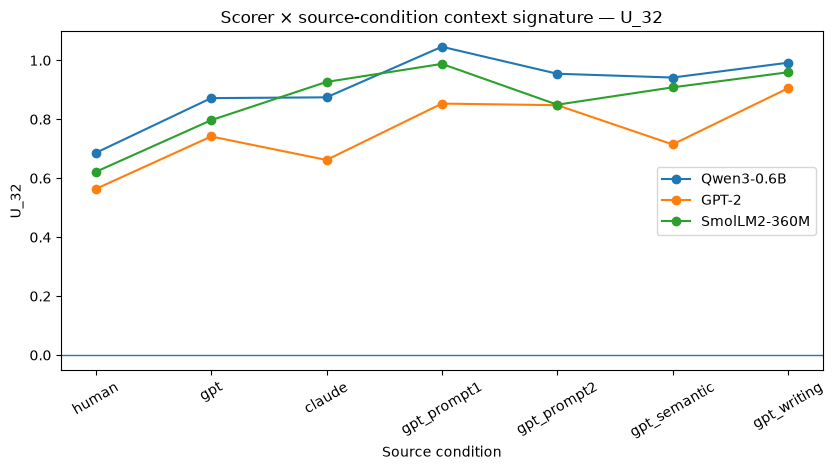

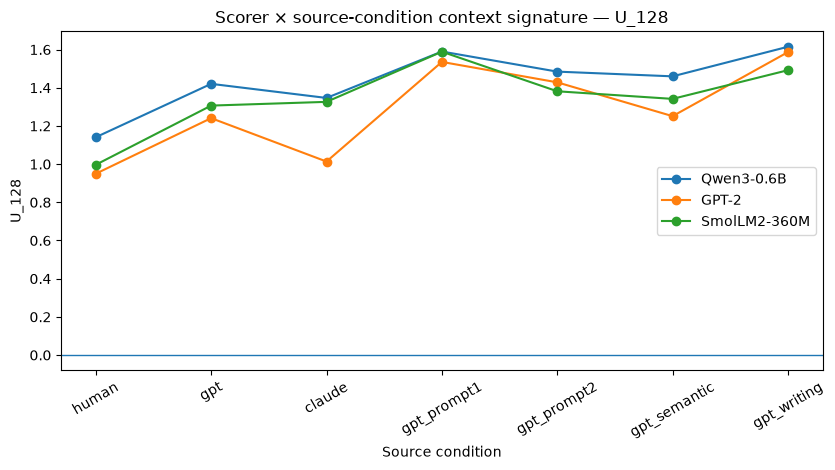

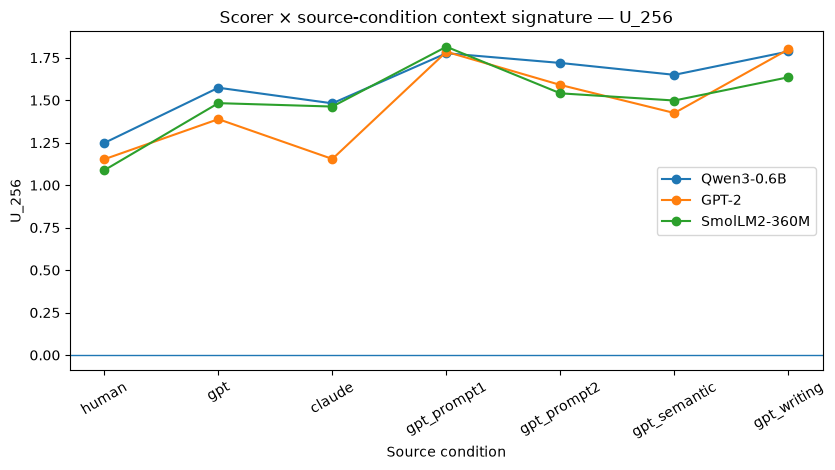

In [16]:

for metric in U_METRICS:
    fig, ax = plt.subplots(figsize=(8.5, 4.8))

    for scorer in SCORERS:
        q = (
            cell_means[
                cell_means["scorer"] == scorer
            ]
            .set_index("generator")
            .reindex(SOURCE_ORDER)
        )

        ax.plot(
            SOURCE_ORDER,
            q[metric],
            marker="o",
            label=scorer,
        )

    ax.axhline(0, linewidth=1)
    ax.set_ylabel(metric)
    ax.set_xlabel("Source condition")
    ax.set_title(
        f"Scorer × source-condition context signature — {metric}"
    )
    ax.tick_params(
        axis="x",
        rotation=30,
    )
    ax.legend()
    fig.tight_layout()

    stem = metric.lower()

    fig.savefig(
        FIGURES / f"scorer_generator_signature_{stem}.pdf",
        bbox_inches="tight",
    )
    fig.savefig(
        FIGURES / f"scorer_generator_signature_{stem}.png",
        dpi=220,
        bbox_inches="tight",
    )

    plt.show()



### Human-relative contrasts with bootstrap intervals


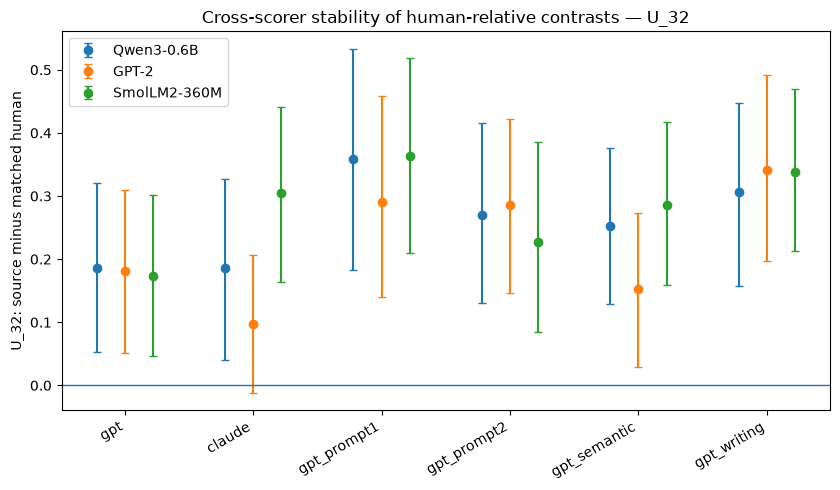

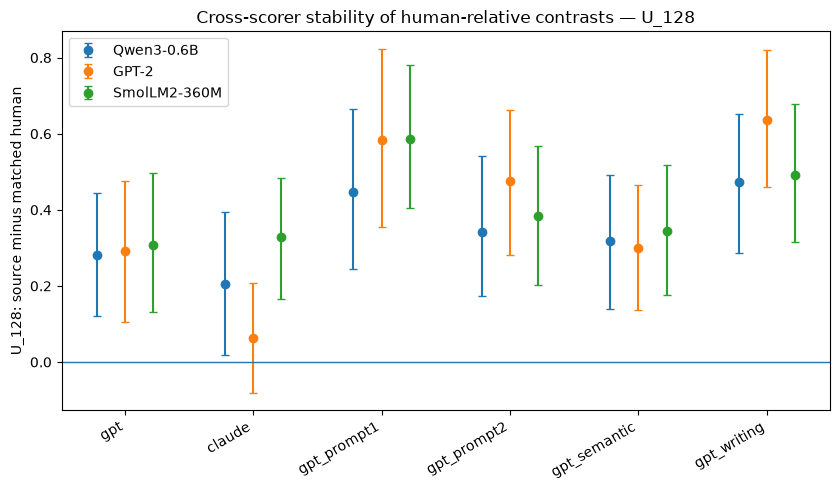

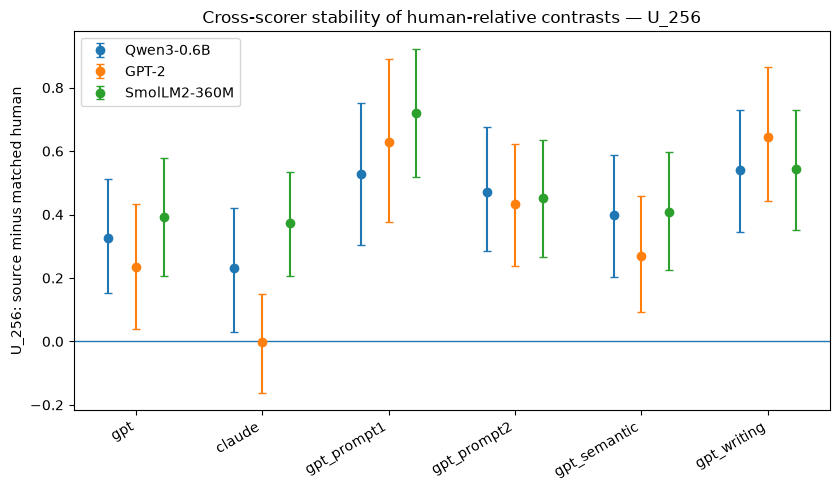

In [17]:

for metric in U_METRICS:
    q = contrast_ci[
        contrast_ci["metric"] == metric
    ].copy()

    generators = [
        g for g in SOURCE_ORDER
        if g != "human"
    ]

    fig, ax = plt.subplots(figsize=(8.5, 5.0))

    x = np.arange(len(generators))
    offsets = np.linspace(
        -0.22,
        0.22,
        len(SCORERS),
    )

    for offset, scorer in zip(
        offsets,
        SCORERS,
    ):
        s = (
            q[q["scorer"] == scorer]
            .set_index("generator")
            .reindex(generators)
        )

        y = s["boot_mean"].to_numpy()
        lo = y - s["ci_low"].to_numpy()
        hi = s["ci_high"].to_numpy() - y

        ax.errorbar(
            x + offset,
            y,
            yerr=np.vstack([lo, hi]),
            fmt="o",
            capsize=3,
            label=scorer,
        )

    ax.axhline(0, linewidth=1)
    ax.set_xticks(x)
    ax.set_xticklabels(
        generators,
        rotation=30,
        ha="right",
    )
    ax.set_ylabel(
        f"{metric}: source minus matched human"
    )
    ax.set_title(
        f"Cross-scorer stability of human-relative contrasts — {metric}"
    )
    ax.legend()
    fig.tight_layout()

    stem = metric.lower()

    fig.savefig(
        FIGURES / f"scorer_generator_human_contrast_{stem}.pdf",
        bbox_inches="tight",
    )
    fig.savefig(
        FIGURES / f"scorer_generator_human_contrast_{stem}.png",
        dpi=220,
        bbox_inches="tight",
    )

    plt.show()


In [18]:
# ================================================================
# Calibrate scorer × source interaction against main-effect sizes
# ================================================================

def additive_component_fractions(mat):
    """
    mat: scorer x source-condition matrix of aggregate means.

    Returns fractions of total centered sum-of-squares attributable
    to scorer main effect, source main effect, and interaction.
    """
    mat = np.asarray(mat, dtype=float)

    grand = mat.mean()

    scorer_mean = mat.mean(
        axis=1,
        keepdims=True,
    )

    source_mean = mat.mean(
        axis=0,
        keepdims=True,
    )

    scorer_component = (
        scorer_mean - grand
    )

    source_component = (
        source_mean - grand
    )

    interaction = (
        mat
        - scorer_mean
        - source_mean
        + grand
    )

    total_ss = np.square(
        mat - grand
    ).sum()

    # Broadcast main effects over the full S x G table.
    scorer_ss = (
        mat.shape[1]
        * np.square(scorer_component).sum()
    )

    source_ss = (
        mat.shape[0]
        * np.square(source_component).sum()
    )

    interaction_ss = np.square(
        interaction
    ).sum()

    return {
        "scorer_fraction":
            scorer_ss / total_ss,
        "source_fraction":
            source_ss / total_ss,
        "interaction_fraction":
            interaction_ss / total_ss,
        "sum":
            (
                scorer_ss
                + source_ss
                + interaction_ss
            ) / total_ss,
    }


component_rows = []

for metric in [
    "U_32",
    "U_128",
    "U_256",
]:
    mat = (
        cell_means
        .pivot(
            index="scorer",
            columns="generator",
            values=metric,
        )
        .reindex(
            index=list(SCORERS),
            columns=SOURCE_ORDER,
        )
        .to_numpy()
    )

    component_rows.append({
        "metric": metric,
        **additive_component_fractions(mat),
    })


component_summary = pd.DataFrame(
    component_rows
)

display(component_summary)

component_summary.to_csv(
    RESULTS
    / "scorer_generator_additive_component_fractions.csv",
    index=False,
)

,metric,scorer_fraction,source_fraction,interaction_fraction,sum
0,U_32,0.250572,0.668203,0.081225,1.0
1,U_128,0.099433,0.821234,0.079334,1.0
2,U_256,0.068222,0.843163,0.088615,1.0


In [19]:
# Bootstrap scorer/source/interaction component fractions.

component_boot_rows = []

rng = np.random.RandomState(2205)

group_ids = np.array(
    sorted(scores["group_id"].unique())
)

for b in tqdm(
    range(N_BOOT),
    desc="component bootstrap",
):
    sampled = rng.choice(
        group_ids,
        size=len(group_ids),
        replace=True,
    )

    bs = pd.concat(
        [
            scores[
                scores["group_id"] == gid
            ]
            for gid in sampled
        ],
        ignore_index=True,
    )

    means = (
        bs
        .groupby(
            ["scorer", "generator"]
        )[
            ["U_32", "U_128", "U_256"]
        ]
        .mean()
        .reset_index()
    )

    for metric in [
        "U_32",
        "U_128",
        "U_256",
    ]:
        mat = (
            means
            .pivot(
                index="scorer",
                columns="generator",
                values=metric,
            )
            .reindex(
                index=list(SCORERS),
                columns=SOURCE_ORDER,
            )
            .to_numpy()
        )

        parts = additive_component_fractions(
            mat
        )

        component_boot_rows.append({
            "boot": b,
            "metric": metric,
            **parts,
        })


component_boot = pd.DataFrame(
    component_boot_rows
)

component_boot_summary = (
    component_boot
    .groupby("metric")
    .agg(
        scorer_median=(
            "scorer_fraction",
            "median",
        ),
        scorer_lo=(
            "scorer_fraction",
            lambda x: np.quantile(x, .025),
        ),
        scorer_hi=(
            "scorer_fraction",
            lambda x: np.quantile(x, .975),
        ),
        source_median=(
            "source_fraction",
            "median",
        ),
        source_lo=(
            "source_fraction",
            lambda x: np.quantile(x, .025),
        ),
        source_hi=(
            "source_fraction",
            lambda x: np.quantile(x, .975),
        ),
        interaction_median=(
            "interaction_fraction",
            "median",
        ),
        interaction_lo=(
            "interaction_fraction",
            lambda x: np.quantile(x, .025),
        ),
        interaction_hi=(
            "interaction_fraction",
            lambda x: np.quantile(x, .975),
        ),
    )
    .reset_index()
)

display(component_boot_summary)

component bootstrap: 100%|██████████████████████████████████████████████████████████████████████████| 2000/2000 [01:57<00:00, 16.98it/s]


,metric,scorer_median,scorer_lo,scorer_hi,source_median,source_lo,source_hi,interaction_median,interaction_lo,interaction_hi
0,U_128,0.095517,0.030795,0.197333,0.776925,0.641023,0.875317,0.123086,0.056550,0.230136
1,U_256,0.067097,0.017510,0.156447,0.801783,0.677619,0.888407,0.126665,0.062614,0.225714
2,U_32,0.227227,0.109322,0.374409,0.628166,0.477806,0.763870,0.140319,0.064069,0.258935



# Decision table

Use the following logic before adding anything to the paper.

| Outcome | Interpretation |
|---|---|
| High machine-signature correlation + stable human-relative signs | Strong evidence that relative dependency traces survive scorer changes |
| Large shifts in absolute \(L_k\), but stable \(U(k)\) contrasts | Exactly the desired scorer-relative observation story |
| Low document-level agreement but high aggregate source agreement | Output property is population-level, not a per-document invariant |
| High scorer × source interaction but preserved human/machine direction | Trace exists, but magnitude is observation-model dependent |
| Source ordering reverses across scorers | Strong warning against treating \(U(k)\) as scorer-invariant |
| Only Qwen shows the headline contrast | Construct interpretation needs to remain explicitly Qwen-relative |

Do **not** optimize the scorer set or source subset after seeing the result. If a larger
confirmatory rerun is needed, keep the same three scorers, same four contexts, same
eligibility rule, and only increase `N_GROUPS`.



# Conclusion template

Fill this only after the full matrix has run.

### Aggregate source invariance
- \(U(32)\): [signature correlations / interaction]
- \(U(128)\): [...]
- \(U(256)\): [...]

### Human-relative robustness
- Number of machine conditions with same contrast direction under every scorer: [...]
- Conditions with meaningful scorer interaction: [...]

### Observation-model dependence
- Absolute \(L_k\) agreement: [...]
- Context-utility agreement: [...]
- Document-level agreement: [...]

### Construct conclusion
Choose one, based on evidence:

1. **Strong invariance:** source-dependent context-range organization is robustly
   observable across independent scorers.
2. **Relative invariance:** source contrasts are stable, but magnitudes/document rankings
   remain scorer-specific.
3. **Substantial interaction:** context utility should be interpreted primarily as a
   scorer-relative measurement rather than a scorer-invariant text property.

### Follow-up gate

Only if this notebook shows a scientifically meaningful scorer × source interaction
should we spend more compute on:

- a larger \(N_{\mathrm{groups}}\) rerun;
- RAID generators with genuinely different model families;
- scorer × generator intervention replication.

Do not automatically expand the matrix merely because more models exist.
